# Etapa 3 Modelo predictivo

**Pregunta:** ¿Qué características conocidas al momento de la compra predicen una entrega tardía?

**Fuente:** capa `lake.silver` en RustFS (`s3a://olist/warehouse/lake/silver/`).


**Variable objetivo:** `tarde` (bool) — `dias_atraso > 0`.

## 1. SparkSession S3A + Iceberg

In [1]:
import os
from pyspark.sql import SparkSession

RUSTFS_ENDPOINT = os.environ.get('RUSTFS_ENDPOINT', 'http://rustfs:9000')
S3_KEY  = os.environ.get('AWS_ACCESS_KEY_ID',     'rustfsadmin')
S3_SEC  = os.environ.get('AWS_SECRET_ACCESS_KEY', 'rustfsadmin123')

JARS = ','.join([
    '/opt/spark/extra-jars/iceberg-spark-runtime-4.1_2.13-1.11.0.jar',
    '/opt/spark/extra-jars/hadoop-aws-3.4.2.jar',
    '/opt/spark/extra-jars/aws-sdk-bundle-v2-2.29.52.jar',
])

spark = (
    SparkSession.builder
    .appName('etapa3-modelos')
    .master('local[*]')
    .config('spark.jars', JARS)
    # S3A → RustFS
    .config('spark.hadoop.fs.s3a.impl',                   'org.apache.hadoop.fs.s3a.S3AFileSystem')
    .config('spark.hadoop.fs.s3a.endpoint',               RUSTFS_ENDPOINT)
    .config('spark.hadoop.fs.s3a.access.key',             S3_KEY)
    .config('spark.hadoop.fs.s3a.secret.key',             S3_SEC)
    .config('spark.hadoop.fs.s3a.path.style.access',      'true')
    .config('spark.hadoop.fs.s3a.connection.ssl.enabled', 'false')
    # Iceberg
    .config('spark.sql.extensions',
            'org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions')
    .config('spark.sql.catalog.lake',           'org.apache.iceberg.spark.SparkCatalog')
    .config('spark.sql.catalog.lake.type',      'hadoop')
    .config('spark.sql.catalog.lake.warehouse', 's3a://olist/warehouse')
    .getOrCreate()
)
spark.sparkContext.setLogLevel('ERROR')
print(f'Spark {spark.version}  |  RustFS: {RUSTFS_ENDPOINT}')

26/10/19 11:53:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.1.3  |  RustFS: http://rustfs:9000


## 2. Tablas disponibles en `lake.silver`

In [2]:
spark.sql("SHOW TABLES IN lake.silver").show(30, truncate=False)

SLF4J: Failed to load class "org.slf4j.impl.StaticLoggerBinder".
SLF4J: Defaulting to no-operation (NOP) logger implementation
SLF4J: See http://www.slf4j.org/codes.html#StaticLoggerBinder for further details.


+---------+--------------+-----------+
|namespace|tableName     |isTemporary|
+---------+--------------+-----------+
|silver   |cuarentena    |false      |
|silver   |geo_cep       |false      |
|silver   |envios        |false      |
|silver   |sellers       |false      |
|silver   |ciudades_geo  |false      |
|silver   |order_items   |false      |
|silver   |products      |false      |
|silver   |order_reviews |false      |
|silver   |customers     |false      |
|silver   |order_payments|false      |
|silver   |orders        |false      |
|silver   |pedidos       |false      |
+---------+--------------+-----------+



In [3]:
import pandas as pd

silver_tables = [
    'pedidos', 'envios', 'orders', 'order_items', 'order_reviews',
    'order_payments', 'customers', 'sellers', 'products', 'geo_cep',
    'ciudades_geo', 'cuarentena',
]

resumen = []
for t in silver_tables:
    try:
        n = spark.table(f'lake.silver.{t}').count()
        cols = len(spark.table(f'lake.silver.{t}').columns)
        resumen.append({'tabla': t, 'filas': n, 'columnas': cols, 'ok': '✓'})
    except Exception as e:
        resumen.append({'tabla': t, 'filas': 0, 'columnas': 0, 'ok': f'✗ {e}'})

pd.DataFrame(resumen).style.hide(axis='index')

tabla,filas,columnas,ok
pedidos,99441,53,✓
envios,100010,28,✓
orders,99441,27,✓
order_items,112650,10,✓
order_reviews,98673,9,✓
order_payments,103886,7,✓
customers,99441,8,✓
sellers,3095,7,✓
products,32951,14,✓
geo_cep,19011,5,✓


## Tabla principal: `lake.silver.pedidos`

Contiene una fila por pedido con todas las métricas derivadas: tiempos, flags de calidad,
datos del cliente, vendedor, pago y reseña.

In [4]:
pedidos = spark.table('lake.silver.pedidos')
print(f'Filas: {pedidos.count():,}  |  Columnas: {len(pedidos.columns)}')
pedidos.printSchema()

Filas: 99,441  |  Columnas: 53
root
 |-- order_id: string (nullable = true)
 |-- customer_zip_code_prefix: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)
 |-- t_aprobacion: double (nullable = true)
 |-- t_despacho: double (nullable = true)
 |-- t_transito: double (nullable = true)
 |-- t_total: double (nullable = true)
 |-- dias_atraso: integer (nullable = true)
 |-- tarde: boolean (nullable = true)
 |-- holgura_promesa: integer (nullable = true)
 |-- dias_prometidos: integer (nullable = true)
 |-- mes_compra: string (nullable = true)
 |-- fecha_compra: date (nullable = true)
 |-- en_periodo_util: boolean (nullable = true)
 |

In [7]:
envios = spark.table('lake.silver.envios')
print(f'Filas: {envios.count():,}  |  Columnas: {len(envios.columns)}')
envios.printSchema()

Filas: 100,010  |  Columnas: 28
root
 |-- seller_id: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- n_items: long (nullable = true)
 |-- precio: decimal(20,2) (nullable = true)
 |-- flete: decimal(20,2) (nullable = true)
 |-- categoria_principal: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- tarde: boolean (nullable = true)
 |-- dias_atraso: integer (nullable = true)
 |-- review_score: integer (nullable = true)
 |-- review_negativa: boolean (nullable = true)
 |-- customer_state: string (nullable = true)
 |-- customer_region: string (nullable = true)
 |-- ciudad_uf_cliente: string (nullable = true)
 |-- seller_state: string (nullable = true)
 |-- seller_region: string (nullable = true)
 |-- ciudad_uf_vendedor: string (nullable = true)
 |-- customer_lat: double (nullable = true)
 |-- customer_lng: double (nullable = true)
 |-- seller_lat: double (nullable = true)
 |-- seller_lng: double (nullable = true)
 |-- distancia_km: double (nullab

In [5]:
from pyspark.sql import functions as F
from pyspark.sql import Window

# Distribución de la variable objetivo 
(
    pedidos
    .filter(F.col('en_periodo_util') & (F.col('order_status') == 'delivered'))
    .groupBy('tarde')
    .agg(F.count('*').alias('n'))
    .withColumn('pct', F.round(F.col('n') / F.sum('n').over(
        Window.rowsBetween(Window.unboundedPreceding, Window.unboundedFollowing)) * 100, 2))
    .orderBy('tarde')
    .show()
)

+-----+-----+----+
|tarde|    n| pct|
+-----+-----+----+
| NULL|    8|0.01|
|false|89672|93.2|
| true| 6531|6.79|
+-----+-----+----+



# Modelos 
 
* LogisticRegression: modelo la **probabilidad** de que un pedido llegue **tarde**:
$$P(\text{tarde}=1 \mid x) = \sigma(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k), \qquad \sigma(z) = \frac{1}{1+e^{-z}}$$

# Variable Target

* desbalance de la clase objetivo -> hay que balancear
* Métrica PR‑AUC, o F1-score. No usamos accuracy (alrededor del 7 % de los pedidos llega tarde)
* eliminar filas donde target is null
* Los desbalances de clase se tratan con weightCol.
* La imputación va dentro del Pipeline y se ajusta solo con el conjunto de entrenamiento

## 4. Variables para el modelo

Solo se usan variables conocidas **al momento de la compra**.
Las columnas de despacho, entrega y tránsito quedan excluidas.

In [24]:
# Columnas conocidas solo después de la compra
desconocidas = {
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    't_aprobacion', 't_despacho', 't_transito', 't_total',
    'dias_atraso', 'holgura_promesa',
    'despacho_fuera_plazo', 'exceso_vendedor', 'exceso_transporte',
    'flag_despacho_antes_aprobacion', 'flag_entrega_antes_despacho',
    'flag_entrega_antes_compra',
    'review_score', 'review_negativa', 'resena_antes_entrega',
    'transito_asignado',
}

# Features candidatas conocidas al comprar
features = [
    'dias_prometidos',          
    'mes_compra',              
    'customer_state',
    'customer_region',
    'n_items',
    'n_vendedores',
    'categoria_principal',
    'peso_medio_g',
    'volumen_medio_cm3',
    'flag_peso_invalido',
    'payment_type',
    'pago_total',
    'multi_vendedor',
]

# Verificar que ninguna sea prohibida
leak = set(features) & desconocidas
assert not leak, f'FUGA DE DATOS: {leak}'
print(f'Features candidatas: {len(features)} sin fuga de datos')

Features candidatas: 13 sin fuga de datos


In [8]:
pedidos.groupby("mes_compra").count().show()

+----------+-----+
|mes_compra|count|
+----------+-----+
|   2018-10|    4|
|   2017-09| 4285|
|   2017-10| 4631|
|   2018-06| 6167|
|   2017-05| 3700|
|   2017-11| 7544|
|   2018-03| 7211|
|   2018-02| 6728|
|   2017-03| 2682|
|   2016-12|    1|
|   2017-08| 4331|
|   2016-09|    4|
|   2017-06| 3245|
|   2016-10|  324|
|   2017-02| 1780|
|   2017-04| 2404|
|   2018-05| 6873|
|   2018-08| 6512|
|   2017-07| 4026|
|   2017-12| 5673|
+----------+-----+
only showing top 20 rows


In [10]:
# mes compra es unico. Mes año sería mas razonavble 
pedidos.select(F.month(F.col("mes_compra")).alias("mes_anio")).show()

+--------+
|mes_anio|
+--------+
|       4|
|       2|
|      12|
|       7|
|       5|
|       1|
|      11|
|       7|
|       8|
|       3|
|       9|
|       8|
|       6|
|      12|
|       3|
|       5|
|       5|
|       2|
|       8|
|       1|
+--------+
only showing top 20 rows


In [22]:
# Agregar informacion del vendedor: problema es que un pedido tiene n venderores:
# (en la práctica los pedidos con varios vendedores son pocos, del orden del 1 % al 3 % según lo que vimos)
# con F.struct(...) nos quedamos el  un vendedor: el que tiene mayor distnacia, esto  es sollo  un criterio

critico = (envios
    .groupBy("order_id")
    .agg(F.max(F.struct("distancia_km", 
                        "seller_id", 
                        "seller_state", 
                        "tramo_distancia", 
                        "seller_region",
                        "intraurbana",
                        "mismo_estado",
                       ))
          .alias("c"),
         F.countDistinct("seller_state").alias("n_estados_vendedor"))
    .select("order_id",
            F.col("c.distancia_km").alias("distancia_critica_km"),
            F.col("c.seller_id").alias("seller_id_critico"),
            F.col("c.seller_state").alias("seller_state_critico"),
            F.col("c.seller_region").alias("seller_region_critico"),
            F.col("c.intraurbana").alias("intraurbana"),
            F.col("c.mismo_estado").alias("mismo_estado"),
            F.col("c.tramo_distancia").alias("tramo_critico"),
            "n_estados_vendedor"))

df_features = pedidos.join(critico, on='order_id', how='left')

In [26]:
# holgura "order_estimated_delivery_date" - "order_delivered_customer_date")
df_features = df_features.withColumn("mes_anio", F.month(F.col("mes_compra")))

In [27]:
df_features.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- customer_zip_code_prefix: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)
 |-- t_aprobacion: double (nullable = true)
 |-- t_despacho: double (nullable = true)
 |-- t_transito: double (nullable = true)
 |-- t_total: double (nullable = true)
 |-- dias_atraso: integer (nullable = true)
 |-- tarde: boolean (nullable = true)
 |-- holgura_promesa: integer (nullable = true)
 |-- dias_prometidos: integer (nullable = true)
 |-- mes_compra: string (nullable = true)
 |-- fecha_compra: date (nullable = true)
 |-- en_periodo_util: boolean (nullable = true)
 |-- flag_aprobacion_antes_compra

In [43]:
var_features =  [
            "tarde",
            "distancia_critica_km",
            "seller_state_critico",
            "seller_region_critico",
            "intraurbana",
            "mismo_estado",
            "tramo_critico",
            "customer_state",
            "customer_region", 
            "n_items", # long (nullable = true)
            "n_vendedores", #: long (nullable = true)
            "precio_total", #: decimal(20,2) (nullable = true)
            "flete_total", #: decimal(20,2) (nullable = true)
            "peso_medio_g", #: double (nullable = true)
            "volumen_medio_cm3", #: double (nullable = true)
            "categoria_principal", #: string (nullable = true)
            "payment_type", #: string (nullable = true)
            "pago_total", #: decimal(20,2) (nullable = true)
       
            "gmv", #: decimal(21,2) (nullable = true)
            "diff_pago", #: decimal(22,2) (nullable = true)
            "multi_vendedor", #: boolean (nullable = true)
            "intraurbana", #: boolean (nullable = true)
            "mismo_estado", #: boolean (nullable = true)
            "tramo_critico", #: string (nullable = true)
            "n_estados_vendedor", #: long (nullable = true)
            "mes_anio", #: integer (nullable = true)
]

In [44]:
numerical =  []
categorical = []
for c, d in df_features.select(var_features).dtypes:
    if d in ["double", "int", "decimal(20,2)", "long"]:
        numerical.append(c)
    else:
        categorical.append(c)

In [47]:
print(f"Numerical: {numerical}")
print(f"Categorical: {categorical}")

Numerical: ['distancia_critica_km', 'precio_total', 'flete_total', 'peso_medio_g', 'volumen_medio_cm3', 'pago_total', 'mes_anio']
Categorical: ['tarde', 'seller_state_critico', 'seller_region_critico', 'intraurbana', 'mismo_estado', 'tramo_critico', 'customer_state', 'customer_region', 'n_items', 'n_vendedores', 'categoria_principal', 'payment_type', 'gmv', 'diff_pago', 'multi_vendedor', 'intraurbana', 'mismo_estado', 'tramo_critico', 'n_estados_vendedor']


In [48]:
(
    df_features
    .select(numerical)
    .describe().toPandas()
)

,summary,distancia_critica_km,precio_total,flete_total,peso_medio_g,volumen_medio_cm3,pago_total,mes_anio
0,count,98176,98666,98666,98650,98650,99440,99441
1,mean,602.6502617047539,137.754076,22.823562,2103.1755387602775,15221.598215640586,160.990267,6.032220110417232
2,stddev,594.159039510543,210.64514531166358,21.65090948046283,3756.800238128275,23368.209896804638,221.9512566132588,3.2329986758604834
3,min,0.0,0.85,0.00,0.0,168.0,0.00,1
4,max,3579.2682818646545,13440.00,1794.96,40425.0,296208.0,13664.08,12


In [23]:
# Estadísticas de features numéricas
features_num = ['dias_prometidos', 'n_items', 'peso_medio_g', 'volumen_medio_cm3', 'pago_total']
(
    df_features
    .filter(F.col('en_periodo_util') & (F.col('order_status') == 'delivered'))
    .select(features_num + ['tarde'])
    .describe()
    .show()
)

+-------+-----------------+------------------+------------------+------------------+------------------+
|summary|  dias_prometidos|           n_items|      peso_medio_g| volumen_medio_cm3|        pago_total|
+-------+-----------------+------------------+------------------+------------------+------------------+
|  count|            96211|             96211|             96195|             96195|             96211|
|   mean|24.28481150803962|1.1420731517186185|2097.8114877630646|15145.172817086233|        159.814111|
| stddev|8.601206091751896| 0.538440256359049| 3744.598714389305| 23215.19631023327|218.88163462516908|
|    min|                3|                 1|               0.0|             168.0|              9.59|
|    max|              156|                21|           40425.0|          296208.0|          13664.08|
+-------+-----------------+------------------+------------------+------------------+------------------+



In [52]:
df_features.select([F.mode(c).alias(c) for c in categorical]).toPandas()

,tarde,seller_state_critico,seller_region_critico,intraurbana,mismo_estado,tramo_critico,customer_state,customer_region,n_items,n_vendedores,categoria_principal,payment_type,gmv,diff_pago,multi_vendedor,intraurbana,mismo_estado,tramo_critico,n_estados_vendedor
0,False,SP,Sudeste,False,False,3_nacional_media (300-1000 km),SP,Sudeste,1,1,bed_bath_table,credit_card,77.57,0.00,False,False,False,3_nacional_media (300-1000 km),1


# Fases para organizar el  procesamiento 

1. **Disponibilidad**: que variables tengo al momento de predecir (leakage) ✅
1. **calidad**:  % de nulos, variabilidad, cardinalidad 
1. **redundancia** a = b + c, pearson, spearman, chramer V
1. **forma de la relación**: 
    * Numéricas: tasa de tardíos (o logit empírico) por deciles. Muestra la forma de la relación.
    * Categóricas: tasa por categoría con intervalo de Wilson.
1. **transformación según el modelo**
1. **selección por validación**
1. **prueba final**.

# 2 Calidad

In [62]:
df = df_features.select(var_features)

# train = df.filter(F.col("fecha_compra") <  "2018-01-01")
# valid = df.filter((F.col("fecha_compra") >= "2018-01-01") & (F.col("fecha_compra") < "2018-04-01"))
# test  = df.filter(F.col("fecha_compra") >= "2018-04-01")

In [75]:
def nulos(df):
    display(df.select([F.count(F.when(F.isnull(F.col(c)),c)).alias(c) for c in df.columns]).toPandas().T)

### 2.1 Nulos 

In [76]:
nulos(df)

,0
tarde,2965
distancia_critica_km,1265
seller_state_critico,775
seller_region_critico,775
intraurbana,775
mismo_estado,775
tramo_critico,775
customer_state,0
customer_region,0
n_items,775


In [77]:
df = df.dropna(subset=['tarde'])
nulos(df)

,0
tarde,0
distancia_critica_km,477
seller_state_critico,0
seller_region_critico,0
intraurbana,0
mismo_estado,0
tramo_critico,0
customer_state,0
customer_region,0
n_items,0


In [81]:
( 
    df.where(F.isnull(F.col("distancia_critica_km")))
    .select(["tramo_critico", "mismo_estado"])
    .groupby("tramo_critico").count().show(truncate=False)
)

+---------------------------+-----+
|tramo_critico              |count|
+---------------------------+-----+
|4_nacional_larga (>1000 km)|477  |
+---------------------------+-----+



## imputacion de faltantes 

Despues de eliminar nulos de tardio (variable target) 

* distancia_critica_km (son todos de larga distanbcia
* eso_medio_g y volumen_medio_cm3: asignar mediana 
* payment  mediana

### 2.2 variablilidad

* variables con muy poca o nula **variabilidad** (por ejemplo, una columna donde todos los valores son iguales) aportan poca información al modelo
* **Cardinalidad**: Se refiere al número de valores únicos o distintos que contiene una columna. Para categoricas define como  se codifica

*  modelos sensibles a la escala (como KNN o Regularización), estandariza primero (media 0, varianza 1).
Elimina variables con varianza < 0.01 <0.01 (o un umbral que tenga sentido en tu escala original).

In [97]:
(
    df
    .filter(F.col('en_periodo_util') & (F.col('order_status') == 'delivered'))
    .select(numerical + ['tarde', 'n_vendedores'])
    .describe()
    .toPandas().T
)

,0,1,2,3,4
summary,count,mean,stddev,min,max
distancia_critica_km,95726,601.6897634033005,592.5422702848325,0.0,3398.5669436011754
precio_total,96203,136.999656,209.12080488215454,0.85,13440.00
flete_total,96203,22.784769,21.566084700641593,0.00,1794.96
peso_medio_g,96187,2097.8200907125497,3744.6868847017763,0.0,40425.0
volumen_medio_cm3,96187,15145.01735306861,23215.771710384775,168.0,296208.0
pago_total,96203,159.813067,218.8894489823961,9.59,13664.08
mes_anio,96203,6.020020165691299,3.226148081834602,1,12
n_vendedores,96203,1.0139080901842978,0.12358809374610494,1,5


### Las variables numericas tienen suficiente varianza (queda ver las que no tiene distribucion normal que pasa con el  método)


In [125]:
# menos del  5% las junto 
umbral = 0.001
exclude = ["intraurbana",
           "tarde", 
           "mismo_estado",
           "multi_vendedor",
           "intraurbana",
           "diff_pago",
           "gmv",
           "n_items",
           "n_vendedores",
           "n_estados_vendedor"
          ]
          
cat_join = {}
tot = df.count()
cols =  [c for c in categorical if c not in exclude]
for c in cols:
    candidatas = df.select(c).groupby(c).agg(
            F.count("*").alias("n"), 
            (F.count("*") / tot).alias("per")
        )   
    candidatas =  candidatas.where(f"per <= {umbral}")
    cat_join[c] = [row[c] for row in candidatas.select(c).collect()]
    print(candidatas.show())
cat_join

+--------------------+---+--------------------+
|seller_state_critico|  n|                 per|
+--------------------+---+--------------------+
|                  RO| 14|1.451138106886687E-4|
|                  PI| 11|1.140179941125254E-4|
|                  AM|  3|3.109581657614329E-5|
|                  PB| 34|3.524192545296239...|
|                  MS| 48|4.975330652182927E-4|
|                  PA|  8|8.292217753638211E-5|
|                  SE|  7|7.255690534433435E-5|
|                  CE| 87|9.017786807081554E-4|
|                  RN| 49|5.078983374103403E-4|
+--------------------+---+--------------------+

None
+---------------------+---+--------------------+
|seller_region_critico|  n|                 per|
+---------------------+---+--------------------+
|                Norte| 25|2.591318048011940...|
+---------------------+---+--------------------+

None
+-------------+---+---+
|tramo_critico|  n|per|
+-------------+---+---+
+-------------+---+---+

None
+--------------+-

{'seller_state_critico': ['RO',
  'PI',
  'AM',
  'PB',
  'MS',
  'PA',
  'SE',
  'CE',
  'RN'],
 'seller_region_critico': ['Norte'],
 'tramo_critico': [],
 'customer_state': ['RR', 'AC', 'AP'],
 'customer_region': [],
 'categoria_principal': ['flowers',
  'la_cuisine',
  'cds_dvds_musicals',
  'furniture_mattress_and_upholstery',
  'party_supplies',
  'cine_photo',
  'music',
  'fashio_female_clothing',
  'arts_and_craftmanship',
  'diapers_and_hygiene',
  'books_imported',
  'home_comfort_2',
  'fashion_childrens_clothes',
  'small_appliances_home_oven_and_coffee',
  'furniture_bedroom',
  'tablets_printing_image',
  'fashion_sport',
  'security_and_services',
  'dvds_blu_ray'],
 'payment_type': [None]}

In [126]:
MIN_TARDIOS = 20

def categorias_raras(df, cols, objetivo="tarde", min_eventos=MIN_TARDIOS):
    """Devuelve {columna: [categorías con menos de min_eventos tardíos]}.
    Los nulos cuentan como una categoría más ('NA')."""
    raras = {}
    for c in cols:
        t = (df.select(F.coalesce(F.col(c).cast("string"), F.lit("NA")).alias(c),
                       F.col(objetivo).cast("int").alias("y"))
               .groupBy(c)
               .agg(F.count("*").alias("n"), F.sum("y").alias("tardios"))
               .where(F.col("tardios") < min_eventos))
        raras[c] = [r[c] for r in t.collect()]
    return raras

raras = categorias_raras(train, ["seller_state_critico", "customer_state",
                                 "categoria_principal", "payment_type"])

NameError: name 'train' is not defined

In [ ]:
def tabla_categorias(df, c, objetivo="tarde"):
    return (df.select(F.coalesce(F.col(c).cast("string"), F.lit("NA")).alias(c),
                      F.col(objetivo).cast("int").alias("y"))
              .groupBy(c)
              .agg(F.count("*").alias("n"), F.sum("y").alias("tardios"),
                   F.round(F.avg("y") * 100, 1).alias("pct_tarde"))
              .orderBy("tardios"))

tabla_categorias(train, "categoria_principal").show(80, truncate=False)

# 2. redundancia+
* a =  b + c: hay variables que son CL de otras
* Numéricas: con correlación de Spearman |ρ| > 0,9, quedarse con una.
* Categóricas: con V de Cramér alta, quedarse con una (estado contra región, por ejemplo).

In [88]:
import math, os
from itertools import combinations
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
import plotly.graph_objects as go

DIR_FIG = "mediciones/modelos/seleccion"
os.makedirs(DIR_FIG, exist_ok=True)

In [89]:
def heatmap_matriz(df_largo, valor, titulo, archivo, zmin=0, zmax=1, escala="Blues"):
    """df_largo: columnas var1, var2 y la columna `valor`. Son k*k filas, un resultado ya agregado."""
    filas = df_largo.collect()
    vars_ = sorted({r["var1"] for r in filas})
    m = {(r["var1"], r["var2"]): r[valor] for r in filas}
    z = [[m.get((a, b)) for b in vars_] for a in vars_]
    texto = [[f"{v:.2f}" if v is not None else "" for v in fila] for fila in z]
    fig = go.Figure(go.Heatmap(z=z, x=vars_, y=vars_, zmin=zmin, zmax=zmax,
                               colorscale=escala, text=texto, texttemplate="%{text}"))
    fig.update_layout(title=titulo, width=750, height=700, yaxis_autorange="reversed")
    fig.write_image(f"{DIR_FIG}/{archivo}.png", scale=2)
    fig.show()

In [90]:
def _a_categoria(df):
    """Pasa todo a string. El nulo cuenta como una categoría más ('NA')."""
    return df.select([F.coalesce(F.col(c).cast("string"), F.lit("NA")).alias(c)
                      for c in df.columns])

def cramer_v_par(df, a, b, corregir=True):
    ct = df.groupBy(a, b).count()
    fila = ct.groupBy(a).agg(F.sum("count").alias("n_a"))
    col = ct.groupBy(b).agg(F.sum("count").alias("n_b"))
    n = ct.agg(F.sum("count")).first()[0]
    s = (ct.join(fila, on=a).join(col, on=b)
           .agg(F.sum(F.col("count") ** 2 / (F.col("n_a") * F.col("n_b")))).first()[0])
    r, k = fila.count(), col.count()
    phi2 = s - 1                                   # chi2 / n
    if corregir:                                   # Bergsma (2013)
        phi2 = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
        r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
        den = min(k_c - 1, r_c - 1)
    else:
        den = min(k - 1, r - 1)
    v = math.sqrt(phi2 / den) if den > 0 else float("nan")
    return v, r, k

def matriz_cramer(df, corregir=True):
    """Devuelve un DataFrame largo: var1, var2, cramer_v, n_cat1, n_cat2."""
    d = _a_categoria(df).cache()
    filas = []
    for a, b in combinations(d.columns, 2):
        v, r, k = cramer_v_par(d, a, b, corregir)
        filas += [(a, b, v, r, k), (b, a, v, k, r)]
    filas += [(c, c, 1.0, None, None) for c in d.columns]
    d.unpersist()
    return spark.createDataFrame(
        filas, "var1 string, var2 string, cramer_v double, n_cat1 int, n_cat2 int")

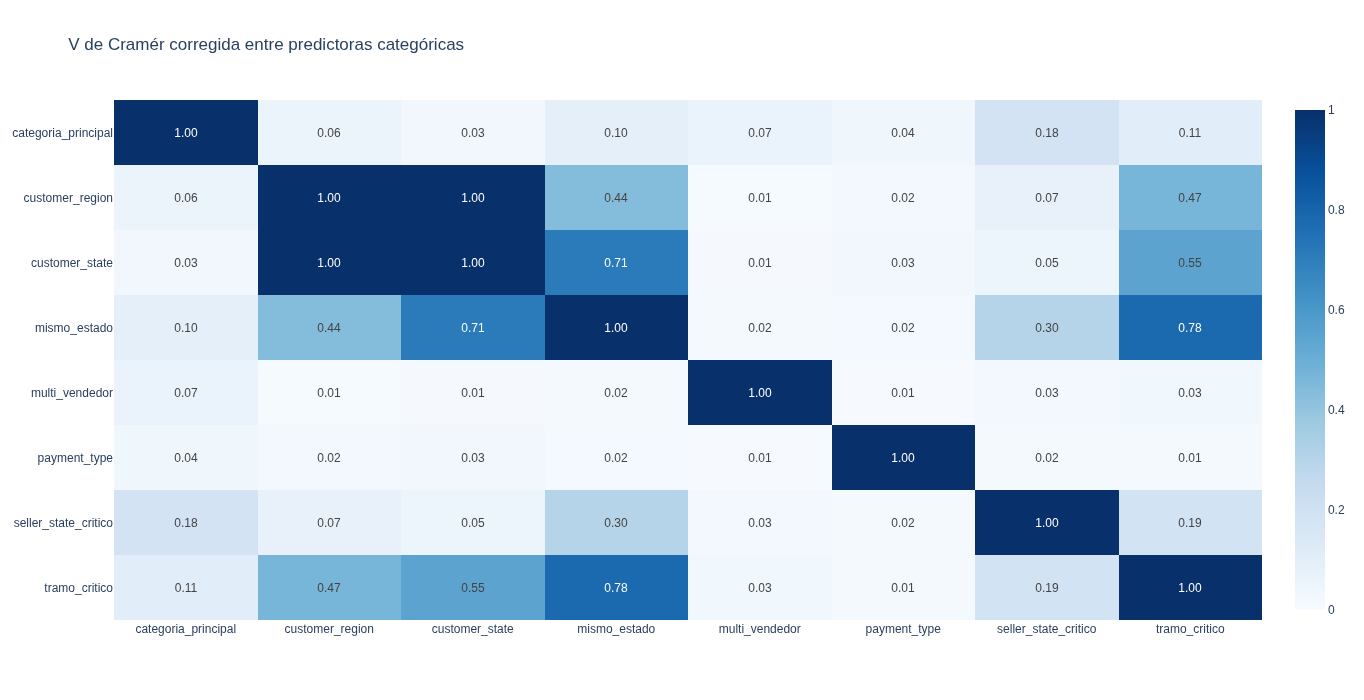

In [93]:
cat = df.select("customer_state", "customer_region", "seller_state_critico",
                   "categoria_principal", "payment_type", "tramo_critico",
                   "mismo_estado", "multi_vendedor")
mc = matriz_cramer(cat)
heatmap_matriz(mc, "cramer_v", "V de Cramér corregida entre predictoras categóricas",
               "cramer_categoricas")

# Analisis  Cramer

* toda la correlacion es geográfica
* customer_region y customer_state: V = 1. La región se deduce del estado. Quitams **customer_region**. tener las dos genera colinealidad perfecta.
* 

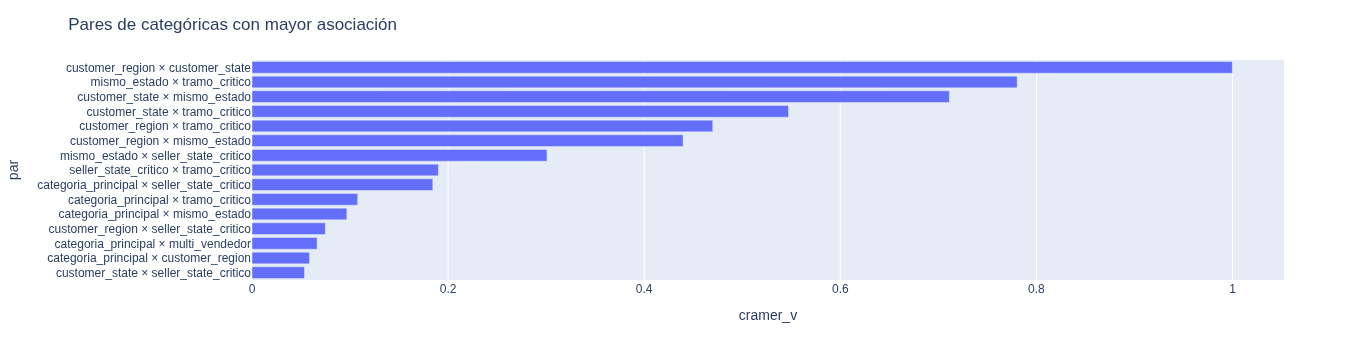

In [98]:
pares = (mc.filter("var1 < var2")
           .withColumn("par", F.concat_ws(" × ", "var1", "var2"))
           .orderBy(F.desc("cramer_v")).limit(15))
fig = pares.plot.barh(x="cramer_v", y="par")
fig.update_layout(title="Pares de categóricas con mayor asociación", yaxis_autorange="reversed")
fig.write_image(f"{DIR_FIG}/cramer_top_pares.png", scale=2)
fig.show()

In [63]:
df.groupby("seller_state_critico").count().orderBy(F.col("count").asc()).show()

+--------------------+-----+
|seller_state_critico|count|
+--------------------+-----+
|                  AC|    1|
|                  AM|    3|
|                  SE|    7|
|                  PA|    8|
|                  PI|   12|
|                  RO|   14|
|                  PB|   35|
|                  MS|   48|
|                  RN|   49|
|                  CE|   91|
|                  MT|  137|
|                  ES|  316|
|                  MA|  392|
|                  PE|  405|
|                  GO|  462|
|                  BA|  568|
|                NULL|  775|
|                  DF|  819|
|                  RS| 1980|
|                  SC| 3641|
+--------------------+-----+
only showing top 20 rows


## 5. Historial del vendedor (sin fuga temporal)

Se calcula para cada pedido usando solo los pedidos **anteriores** a su `fecha_compra`.
Se usa una window function con el marco `ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING`.

In [17]:
from pyspark.sql.window import Window

# Tabla base: pedidos entregados del período útil con seller_id
base = (
    pedidos
    .filter(F.col('en_periodo_util') & (F.col('order_status') == 'delivered'))
    .select(
        'order_id', 'seller_id', 'fecha_compra', 'tarde',
        *FEATURES_CANDIDATAS,
    )
)

# Window: por vendedor, ordenado por fecha de compra, solo filas anteriores
w_hist = (
    Window
    .partitionBy('seller_id')
    .orderBy('fecha_compra')
    .rowsBetween(Window.unboundedPreceding, -1)
)

base_hist = base.withColumn(
    'seller_hist_tardios_previos',
    F.sum(F.col('tarde').cast('int')).over(w_hist),
).withColumn(
    'seller_hist_envios_previos',
    F.count('order_id').over(w_hist),
).withColumn(
    'seller_hist_tasa_tardia',
    F.when(
        F.col('seller_hist_envios_previos') > 0,
        F.col('seller_hist_tardios_previos') / F.col('seller_hist_envios_previos'),
    ).otherwise(None),
)

print(f'Filas con historial del vendedor: {base_hist.count():,}')
base_hist.select(
    'order_id', 'seller_id', 'fecha_compra', 'tarde',
    'seller_hist_envios_previos', 'seller_hist_tasa_tardia'
).show(10)

Filas con historial del vendedor: 96,211
+--------------------+--------------------+------------+-----+--------------------------+-----------------------+
|            order_id|           seller_id|fecha_compra|tarde|seller_hist_envios_previos|seller_hist_tasa_tardia|
+--------------------+--------------------+------------+-----+--------------------------+-----------------------+
|d455a8cb295653b55...|0015a82c2db000af6...|  2017-09-26|false|                         0|                   NULL|
|9dc8d1a6f16f1b898...|0015a82c2db000af6...|  2017-10-12|false|                         1|                    0.0|
|7f39ba4c9052be115...|0015a82c2db000af6...|  2017-10-18|false|                         2|                    0.0|
|3c655487f0c8e34cd...|001cca7ae9ae17fb1...|  2017-02-04|false|                         0|                   NULL|
|eb188a175542057d9...|001cca7ae9ae17fb1...|  2017-02-18|false|                         1|                    0.0|
|67054420c38f2db9d...|001cca7ae9ae17fb1...|  20

## Partición temporal train / test

* El CrossValidator de MLlib mezcla las filas al azar, en nuestro caso  estaríamos mezclando el futuro con el pasado. Mejor usar **TrainValidationSplit** con la partición temporal hecha a mano

    * Entrenar con pedidos hasta **2018-04** inclusive,
    * Hiperparámetros hasta xxxx-xx
    * evaluar con pedidos de **xxxx-xx** en adelante.
    * **binning** se materializa como variables dummy
    * En lugar de código_postal, usamos región, reduciendo los parámetros de N a 7. Ahora tenemos n / 7 = x.xx eventos por parámetro



In [18]:
FECHA_CORTE = '2018-05'

train = base_hist.filter(F.col('mes_compra') < FECHA_CORTE)
test  = base_hist.filter(F.col('mes_compra') >= FECHA_CORTE)

n_train = train.count()
n_test  = test.count()

print(f'Train:  {n_train:>7,} pedidos  (< {FECHA_CORTE})')
print(f'Test:   {n_test:>7,} pedidos  (≥ {FECHA_CORTE})')
print(f'Total:  {n_train + n_test:>7,}')
print()

# Tasa de tardíos en cada partición
for nombre, df in [('train', train), ('test', test)]:
    tasa = df.agg(F.mean(F.col('tarde').cast('double'))).collect()[0][0]
    print(f'  {nombre}: tasa tardíos = {tasa:.3%}')

Train:   70,853 pedidos  (< 2018-05)
Test:    25,358 pedidos  (≥ 2018-05)
Total:   96,211

  train: tasa tardíos = 7.644%
  test: tasa tardíos = 4.398%


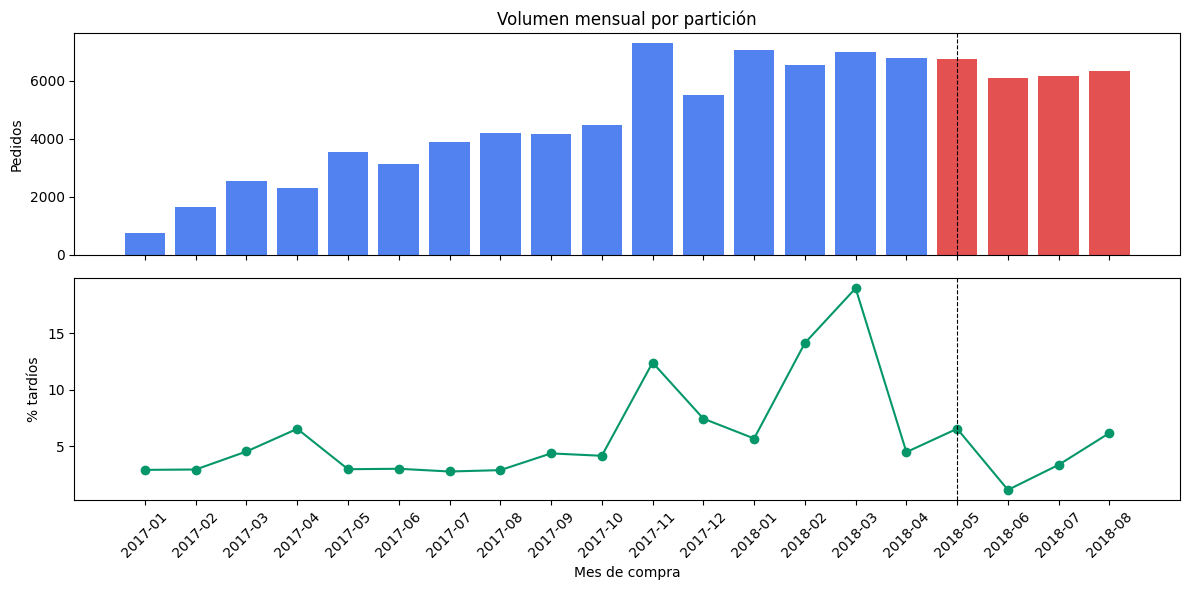

Guardado: graficos/split_train_test.png


In [19]:
# Distribución mensual de train y test (control visual)
import matplotlib.pyplot as plt

df_meses = (
    base_hist
    .groupBy('mes_compra')
    .agg(
        F.count('*').alias('n'),
        F.mean(F.col('tarde').cast('double')).alias('tasa_tardia'),
    )
    .orderBy('mes_compra')
    .toPandas()
)
df_meses['particion'] = df_meses['mes_compra'].apply(
    lambda m: 'train' if m < FECHA_CORTE else 'test'
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

colores = df_meses['particion'].map({'train': '#2563eb', 'test': '#dc2626'})
ax1.bar(df_meses['mes_compra'], df_meses['n'], color=colores, alpha=0.8)
ax1.set_ylabel('Pedidos')
ax1.set_title('Volumen mensual por partición')
ax1.axvline(x=df_meses[df_meses['particion']=='test']['mes_compra'].iloc[0],
            color='k', linestyle='--', linewidth=0.8, label='corte')

ax2.plot(df_meses['mes_compra'], df_meses['tasa_tardia'] * 100,
         marker='o', color='#059669', linewidth=1.5)
ax2.set_ylabel('% tardíos')
ax2.set_xlabel('Mes de compra')
ax2.axvline(x=df_meses[df_meses['particion']=='test']['mes_compra'].iloc[0],
            color='k', linestyle='--', linewidth=0.8)
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('graficos/split_train_test.png', dpi=130, bbox_inches='tight')
plt.show()
print('Guardado: graficos/split_train_test.png')

## Tabla `lake.silver.envios` — features de distancia y ruta

Contiene una fila por ítem (no por pedido). Para el modelo se necesita agregar al nivel pedido.

In [20]:
envios = spark.table('lake.silver.envios')
print(f'Filas: {envios.count():,}  |  Columnas: {len(envios.columns)}')
envios.printSchema()

Filas: 100,010  |  Columnas: 28
root
 |-- seller_id: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- n_items: long (nullable = true)
 |-- precio: decimal(20,2) (nullable = true)
 |-- flete: decimal(20,2) (nullable = true)
 |-- categoria_principal: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- tarde: boolean (nullable = true)
 |-- dias_atraso: integer (nullable = true)
 |-- review_score: integer (nullable = true)
 |-- review_negativa: boolean (nullable = true)
 |-- customer_state: string (nullable = true)
 |-- customer_region: string (nullable = true)
 |-- ciudad_uf_cliente: string (nullable = true)
 |-- seller_state: string (nullable = true)
 |-- seller_region: string (nullable = true)
 |-- ciudad_uf_vendedor: string (nullable = true)
 |-- customer_lat: double (nullable = true)
 |-- customer_lng: double (nullable = true)
 |-- seller_lat: double (nullable = true)
 |-- seller_lng: double (nullable = true)
 |-- distancia_km: double (nullab

In [21]:
# Agregar al nivel pedido: distancia máxima, ruta estado, tramo
envios_agg = (
    envios
    .groupBy('order_id')
    .agg(
        F.max('distancia_km').alias('distancia_max_km'),
        F.first('seller_state').alias('seller_state'),
        F.first('tramo_distancia').alias('tramo_distancia'),
    )
)

envios_agg.show(5)
print(f'Pedidos con distancia: {envios_agg.count():,}')

+--------------------+------------------+------------+--------------------+
|            order_id|  distancia_max_km|seller_state|     tramo_distancia|
+--------------------+------------------+------------+--------------------+
|00018f77f2f0320c5...| 588.5859988579489|          SP|3_nacional_media ...|
|00042b26cf59d7ce6...| 646.4479519758663|          PR|3_nacional_media ...|
|00054e8431b9d7675...|484.72384298953125|          SP|3_nacional_media ...|
|0006ec9db01a64e59...| 566.1504359990058|          SP|3_nacional_media ...|
|000aed2e25dbad2f9...| 38.35490203726987|          SP|    1_local (<50 km)|
+--------------------+------------------+------------+--------------------+
only showing top 5 rows
Pedidos con distancia: 98,666


## 8. Otras tablas silver disponibles

In [10]:
# orders — tabla base de pedidos (sin métricas derivadas)
orders = spark.table('lake.silver.orders')
print('lake.silver.orders')
orders.printSchema()

lake.silver.orders
root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)
 |-- t_aprobacion: double (nullable = true)
 |-- t_despacho: double (nullable = true)
 |-- t_transito: double (nullable = true)
 |-- t_total: double (nullable = true)
 |-- dias_atraso: integer (nullable = true)
 |-- tarde: boolean (nullable = true)
 |-- holgura_promesa: integer (nullable = true)
 |-- dias_prometidos: integer (nullable = true)
 |-- mes_compra: string (nullable = true)
 |-- fecha_compra: date (nullable = true)
 |-- en_periodo_util: boolean (nullable = true)
 |-- flag_aprobacion_antes_compra: boolean (nullable = true)
 |-- flag

In [11]:
# sellers — dimensión de vendedores
sellers = spark.table('lake.silver.sellers')
print('lake.silver.sellers')
sellers.printSchema()

lake.silver.sellers
root
 |-- seller_state: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- seller_zip_code_prefix: string (nullable = true)
 |-- seller_city: string (nullable = true)
 |-- city_canon: string (nullable = true)
 |-- ciudad_uf: string (nullable = true)
 |-- seller_region: string (nullable = true)



In [12]:
# geo_cep — centroides por prefijo CEP
geo = spark.table('lake.silver.geo_cep')
print('lake.silver.geo_cep')
geo.show(5)

lake.silver.geo_cep
+-----+--------+-------------------+-------------------+-------------+
|  zip|n_puntos|            lat_med|            lng_med|geo_confianza|
+-----+--------+-------------------+-------------------+-------------+
|02053|      11| -23.51562097807146| -46.60419862406944|           ok|
|02943|      18| -23.47680107576895|-46.724968262421356|           ok|
|03442|      10| -23.54376624063706|-46.540915920624364|           ok|
|03511|      22|-23.534804735212706| -46.52807057937563|           ok|
|03904|      22|-23.578213986958254| -46.51870739425241|           ok|
+-----+--------+-------------------+-------------------+-------------+
only showing top 5 rows


In [13]:
# cuarentena — pedidos excluidos del análisis y motivo
cuarentena = spark.table('lake.silver.cuarentena')
print(f'Pedidos en cuarentena: {cuarentena.count():,}')
cuarentena.groupBy('motivo').count().orderBy('count', ascending=False).show()

Pedidos en cuarentena: 1,382
+--------------------+-----+
|              motivo|count|
+--------------------+-----+
|fechas del ciclo ...| 1382|
+--------------------+-----+



## 9. Guardar dataset de features (para la celda de modelo)

Une pedidos + historial del vendedor + distancia de envíos.
Guarda como Parquet local para no repetir la lectura de silver en cada run.

In [ ]:
import os
os.makedirs('data/features', exist_ok=True)

features_full = (
    base_hist
    .join(envios_agg, on='order_id', how='left')
)

features_full.write.mode('overwrite').parquet('data/features/pedidos_features.parquet')

n = features_full.count()
cols = len(features_full.columns)
print(f'Dataset guardado: {n:,} filas × {cols} columnas')
print('Ruta: etapa2/notebooks/data/features/pedidos_features.parquet')

In [ ]:
spark.stop()
print('SparkSession cerrada. Silver leído correctamente.')